# Affective Fields

Simple model where the stream of consciousness is modeled as a complex vector field
in complex analysis and the affects like pain, pleasure, craving are modeled as
poles and vortices.
https://en.wikipedia.org/wiki/Complex_analysis

The basic idea is that the stream of consciousness can be modeled as a continuous,
differentiable complex function f(z) living on a Riemann surface. In a healthy,
calm state (homeostasis), f(z) is entirely analytic (holomorphic) - meaning it is smooth,
continuous, differentiable, and lacks any abrupt breaks. The "stream of consciousness"
flows gracefully across the manifold. When a homeostatic boundary is catastrophically
violated (tissue damage, severe trauma, or acute panic), the local control equations
break down or diverge to infinity. In complex analysis, this is known as a singularity — 
specifically a pole or an essential singularity.

The Informational Hole: Just as a physical wound is a hole in the tissue boundary,
a singularity is a point where the function f(z) goes to infinity and fails to be
differentiable. The local smooth flow collapses. This can be modeled as a sink. 
The surrounding information flow is violently pulled toward from this point.
In fluid dynamics, this is a sink or a vortex; in complex analysis, it is a pole.

The question is: can we measure the subjective quality and intensity of a feeling by
the residue of the homeostatic disruption? When our attention loops around a physical
injury or an emotional trauma, then the "weight" we feel (the magnitude of the qualia)
would literally be the residue evaluated at that pole. The pain doesn't just sit at
one point; its affective "spread" and cognitive capture are governed by how the
surrounding informational flow curves around the singularity.

Cauchy's residue theorem evaluates complex line integrals of analytic functions
around closed curves by summing the residues at enclosed singularities. Similarly
Qualia could be defined in this model by summing the residues of the affective "singularities",
i.e. the poles that are linked to the active affects
https://en.wikipedia.org/wiki/Residue_theorem

$$\text{Qualia}(\mathbf{s}) = \underbrace{\frac{1}{2\pi i} \oint_C \frac{\mathcal{S}(z)}{z-s} dz}_{\text{Lossy Self-Model Projection}} = \underbrace{\sum_{k} \mathbf{Res}_k \, \Theta(\mathbf{s}, a_k)}_{\text{Singular Affective Textures}}$$

* A residue of a pole reflects a measurable intensity of an affect which can be calculated in
the model by contour integration

* The phase of the residue is a texture. Real means flux and imaginary means circulation,
while mixtures give spirals. A continuous rotation from craving to pain also has to
pass through the rumination region.

* Capture is a basin. Cognitive capture is related to be basin size of the sink or vortex

In [1]:
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import brentq, fsolve

items {'Pain (sink)': ((-2.5+0j), -0.3183098861837907), 'Craving (vortex)': ((2.5+0j), (-0-0.3183098861837907j)), 'Rumination (spiral sink)': (-2j, (-0.238732414637843-0.238732414637843j)), 'Fear (saddle)': (1.5j, 0)}
affect                                       Res   |Res|  arg Res/π  W(field)
Pain (sink)                  -0.3184   -0.0002j  0.3184     -1.000     +1.00
Craving (vortex)             -0.0001   -0.3181j  0.3181     -0.500     +1.00
Rumination (spiral sink)     -0.2387   -0.2387j  0.3376     -0.750     +1.00
Fear (saddle)                +0.0000   -0.0000j  0.0000        nan     +0.00

All enclosed: Res=-0.5570-0.5570j, W(field)=+1.00
Sum of local W: 3


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3786715580.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3786715580.py:15: RuntimeWarning: divide by zero encountered in scalar divide
  out = sum(c/(z-a) for a,c in poles.values())
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3786715580.py:15: RuntimeWarning: invalid value encountered in scalar divide
  out = sum(c/(z-a) for a,c in poles.values())



Stagnation points (zeros of field):
  z=-1.970-1.286j  index=-1
  z=+1.970-1.286j  index=-1


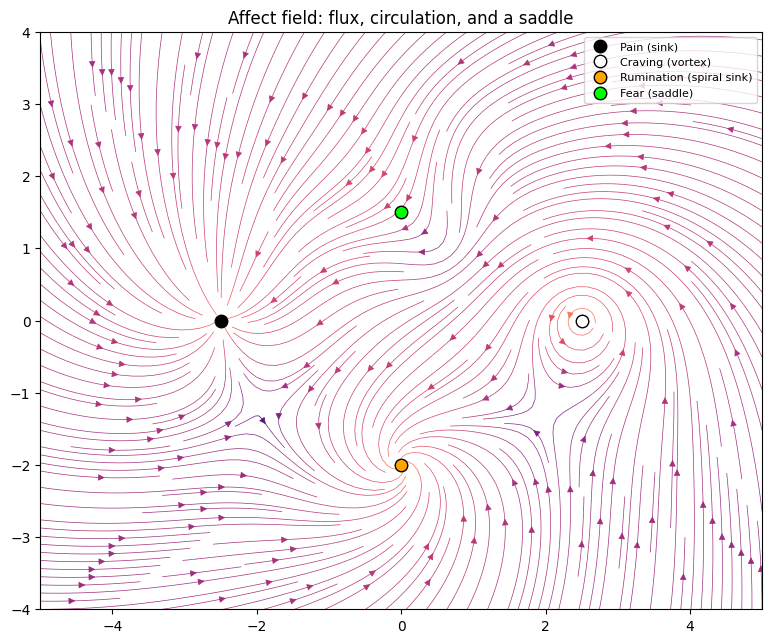

In [2]:
%matplotlib inline

# Each affect is modeled as a feature of the field
# a pole, a zero, or a structure made of several.
# List of poles. Format name: (location, residue of V=u-iw) 
poles = {"Pain (sink)":      (-2.5+0j,  -2/(2*np.pi)),
         "Craving (vortex)": ( 2.5+0j,  -2j/(2*np.pi)),
         "Rumination (spiral sink)": (0-2j, -(1.5+1.5j)/(2*np.pi))}

# A saddle is a zero, not a pole
a_saddle = 0+1.5j

# V = sum of poles
def V(z):
    out = sum(c/(z-a) for a,c in poles.values())
    k, s = 0.6, 1.0
    return out + k*(z-a_saddle)*np.exp(-np.abs(z-a_saddle)**2/s**2)   # fear: localized saddle

# complex conjugate of V(z)
vel = lambda z: np.conj(V(z))

def circ(c, r, N=200001):
    t = np.linspace(0, 2*np.pi, N); return c+r*np.exp(1j*t), 1j*r*np.exp(1j*t), t

def res(c, r):
    z,dz,t = circ(c,r); return np.trapezoid(V(z)*dz,t)/(2j*np.pi)

def W(f, c, r):
    z,_,_ = circ(c,r); a = np.unwrap(np.angle(f(z))); return (a[-1]-a[0])/(2*np.pi)

items = {n:(a,c) for n,(a,c) in poles.items()}
items["Fear (saddle)"]=(a_saddle,0)

print("items", items)
print(f"{'affect':26s}{'Res':>22s}{'|Res|':>8s}{'arg Res/π':>11s}{'W(field)':>10s}")
for n,(a,_) in items.items():
    R = res(a,0.4); ang = np.angle(R)/np.pi if abs(R)>1e-3 else float('nan')
    print(f"{n:26s}{R.real:+10.4f}{R.imag:+10.4f}j{abs(R):8.4f}{ang:11.3f}{W(vel,a,0.4):+10.2f}")
Rall = res(0,5.0); print(f"\nAll enclosed: Res={Rall.real:+.4f}{Rall.imag:+.4f}j, W(field)={W(vel,0,5.0):+.2f}")
print("Sum of local W:", sum(round(W(vel,a,0.4)) for a,_ in items.values()))

X,Y = np.meshgrid(np.linspace(-5,5,500), np.linspace(-4,4,400))
Zg = X+1j*Y
F = vel(Zg)

fig,ax = plt.subplots(figsize=(10,7.5))
sp = ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=2.4,linewidth=0.5)

cols = ["black","white","orange","lime"]
for (n,(a,_)),c in zip(items.items(),cols):
    ax.plot(a.real,a.imag,"o",color=c,ms=9,mec="k",label=n)
    # z,_,_ = circ(a,0.4,300); ax.plot(z.real,z.imag,"--",color=c,lw=1.3)

bg_color = "#fff"
ax.set_facecolor(bg_color)
ax.set_aspect("equal")
ax.legend(loc="upper right",fontsize=8)
ax.set_title("Affect field: flux, circulation, and a saddle")
fig.show()
fig.savefig("affect_field.svg",dpi=130,bbox_inches="tight")

# ---- locate every stagnation point (zero of the field) and its index ----
from scipy.optimize import fsolve
zs=[]
for x0 in np.linspace(-4,4,17):
    for y0 in np.linspace(-3,3,13):
        f=lambda p:[vel(p[0]+1j*p[1]).real, vel(p[0]+1j*p[1]).imag]
        p,info,ier,_=fsolve(f,[x0,y0],full_output=True)
        z=p[0]+1j*p[1]
        if ier==1 and abs(z)<6 and all(abs(z-q)>1e-3 for q in zs) and all(abs(z-a)>0.05 for a,_ in poles.values()):
            zs.append(z)

print("\nStagnation points (zeros of field):")
for z in zs: print(f"  z={z.real:+.3f}{z.imag:+.3f}j  index={W(vel,z,0.05):+.0f}")


* pleasure (source) = real and positive residue Res; |Res| is intensity
* pain (sink pole) = real and negative residue Res, |Res| is intensity
* craving, obsession (vortex pole) = residue Res purely imaginary; describes rotating vortex
* rumination, addiction (sink) = Res complex, with negative real and imaginary parts; a mix of sink and swirl
* fear (sddle node) = movement towards pain, anticipation of it

   t  |Res| sink  |Res| vortex  peak speed  saddle→sink dist
   0      0.3113        0.3113      1.1378            2.9155
   2      0.1359        0.3113      0.2598            1.7959
   4      0.0537        0.3113      0.1439               nan
   6      0.0205        0.3113      0.1257               nan
   8      0.0078        0.3113      0.1220               nan
  10      0.0031        0.3113      0.1210               nan
  12      0.0012        0.3113      0.1209               nan
saddle last exists at t = 3.3000000000000003 ; gone afterwards: True
background vortex speed at sink site: 0.07957747154594767


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3509626351.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3509626351.py:67: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


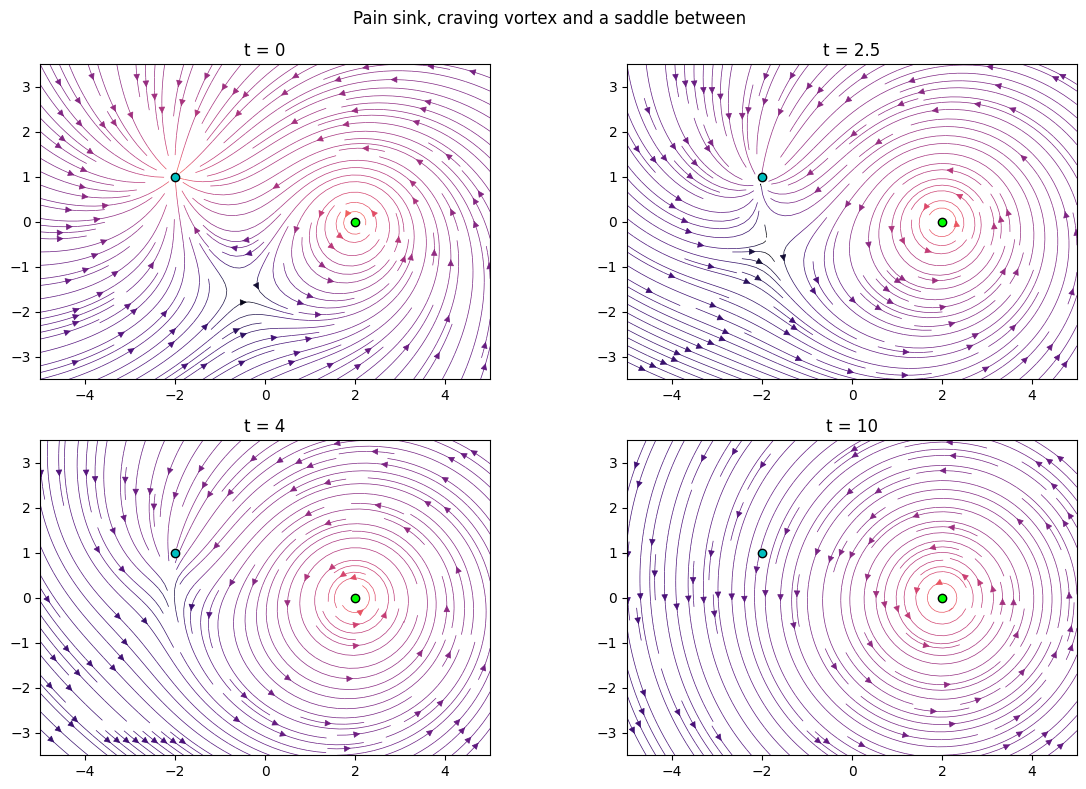

In [3]:
%matplotlib inline

a, b = -2+1j, 2+0j            # pain sink, craving vortex
m0, G, tau = 2.0, 2.0, 3.0    # sink strength, circulation, relief time-constant
eps_v = 0.15
eps = lambda t: 0.15 + 0.15*t         # core radius grows: singularity softens into a well
mm  = lambda t: m0*np.exp(-t/tau)     # boundary restored: strength decays

def vel(z, t):                        # physical field u+iw
    e = eps(t)
    sink = -(mm(t)/(2*np.pi))*(z-a)/(np.abs(z-a)**2+e**2)
    vort = (G/(2*np.pi))*1j*(z-b)/(np.abs(z-b)**2+eps_v**2)
    return sink + vort

def circ(c, r, N=20001):
    th = np.linspace(0, 2*np.pi, N); return c+r*np.exp(1j*th), 1j*r*np.exp(1j*th), th

def residue(c, r, t):                 # (1/2πi)∮ V dz,  V = conj(vel)
    z,dz,th = circ(c,r); return np.trapezoid(np.conj(vel(z,t))*dz, th)/(2j*np.pi)

def peak(c, r, t):
    X,Y = np.meshgrid(np.linspace(-r,r,201), np.linspace(-r,r,201)); Z = c+X+1j*Y
    return np.abs(vel(Z,t))[np.abs(X+1j*Y)<r].max()

def saddle(t):                        # stagnation point between sink and vortex
    c1, c2 = -mm(t)/(2*np.pi), -1j*G/(2*np.pi)
    g = (c1*b + c2*a)/(c1+c2)         # analytic guess (point-pole limit)
    f = lambda p: [vel(p[0]+1j*p[1],t).real, vel(p[0]+1j*p[1],t).imag]
    p,info,ier,_ = fsolve(f, [g.real, g.imag], full_output=True)
    z = p[0]+1j*p[1]
    ok = ier==1 and np.hypot(*f(p))<1e-9 and abs(z-a)<3.5
    return z if ok else np.nan

ts = np.linspace(0, 12, 121)
R_sink = np.array([abs(residue(a,1.0,t)) for t in ts])
R_vort = np.array([abs(residue(b,1.0,t)) for t in ts])
pk     = np.array([peak(a,1.5,t) for t in ts])
sd     = np.array([abs(saddle(t)-a) for t in ts])
print(f"{'t':>4}{'|Res| sink':>12}{'|Res| vortex':>14}{'peak speed':>12}{'saddle→sink dist':>18}")
for i in range(0,121,20): print(f"{ts[i]:4.0f}{R_sink[i]:12.4f}{R_vort[i]:14.4f}{pk[i]:12.4f}{sd[i]:18.4f}")
alive = ~np.isnan(sd)

print("saddle last exists at t =", ts[alive][-1] if alive.any() else None, "; gone afterwards:", (~alive[np.argmax(~alive):]).all())
print("background vortex speed at sink site:", G/(2*np.pi*4))

fig = plt.figure(figsize=(12,8))
gs = fig.add_gridspec(2,2,height_ratios=[1,1])
X,Y = np.meshgrid(np.linspace(-5,5,300), np.linspace(-3.5,3.5,210))
Zg = X+1j*Y

for k,t in enumerate([0,2.5,4,10]):
    ax = fig.add_subplot(gs[k//2,k%2])
    F = vel(Zg,t)
    ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=1.6,linewidth=0.5,norm=plt.Normalize(-2,1))
    s = saddle(t)
    if not np.isnan(s): ax.plot(s.real,s.imag,"wx",ms=9,mew=2)
    ax.plot(a.real,a.imag,"co",mec="k")
    ax.plot(b.real,b.imag,"o",color="lime",mec="k")
    ax.set_facecolor("#fff")
    ax.set_aspect("equal")
    ax.set_title(f"t = {t}")

fig.suptitle("Pain sink, craving vortex and a saddle between")
fig.tight_layout()
fig.show()
fig.savefig("affect_relief_1.svg",dpi=120)
fig.show()

items {'Pleasure (source)': ((-3+0j), 0.3183098861837907), 'Craving (vortex)': ((0.5+0j), (-0-0.3183098861837907j)), 'Pain (sink)': ((2.5-2.5j), (-0.238732414637843+0j)), 'Fear (saddle)': ((-1-0.5j), 0)}
affect                                       Res   |Res|  arg Res/π  W(field)
Pleasure (source)            +0.3127   +0.0030j  0.3127      0.003     +1.00
Craving (vortex)             -0.0151   -0.3296j  0.3300     -0.515     +1.00
Pain (sink)                  -0.2387   +0.0000j  0.2387      1.000     +1.00
Fear (saddle)                -0.0000   -0.0000j  0.0000        nan     +0.00

All enclosed: Res=+0.0796-0.3183j, W(field)=+1.00
Sum of local W: 3


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/2688940695.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/2688940695.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  out = sum(c/(z-a) for a,c in poles.values())
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/2688940695.py:11: RuntimeWarning: invalid value encountered in scalar divide
  out = sum(c/(z-a) for a,c in poles.values())



Stagnation points (zeros of field):
  z=-1.419+2.518j  index=-1
  z=+3.855-0.752j  index=-1


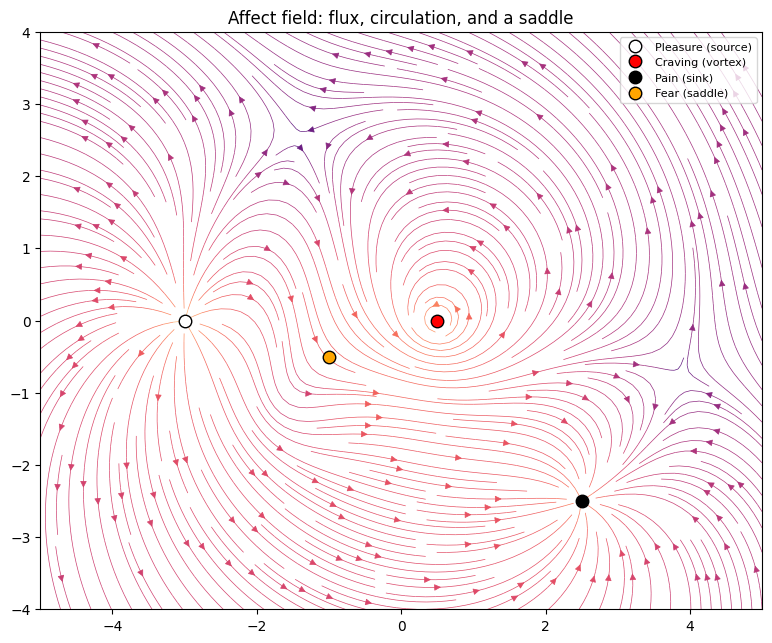

In [4]:
%matplotlib inline

# name: (location, residue of V=u-iw) ; saddle is a zero, not a pole
poles = {"Pleasure (source)": (-3.0+0j,   2/(2*np.pi)),
         "Craving (vortex)": ( 0.5+0j,  -2j/(2*np.pi)),
         "Pain (sink)": (2.5-2.5j, (-1.5+0j)/(2*np.pi))}

a_saddle, k, s = -1-0.5j, 0.6, 1.0

def V(z):
    out = sum(c/(z-a) for a,c in poles.values())
    return out + k*(z-a_saddle)*np.exp(-np.abs(z-a_saddle)**2/s**2)   # fear: localized saddle

vel = lambda z: np.conj(V(z))

def circ(c, r, N=200001):
    t = np.linspace(0, 2*np.pi, N); return c+r*np.exp(1j*t), 1j*r*np.exp(1j*t), t
def res(c, r):
    z,dz,t = circ(c,r); return np.trapezoid(V(z)*dz,t)/(2j*np.pi)
def W(f, c, r):
    z,_,_ = circ(c,r); a = np.unwrap(np.angle(f(z))); return (a[-1]-a[0])/(2*np.pi)

items = {n:(a,c) for n,(a,c) in poles.items()}
items["Fear (saddle)"]=(a_saddle,0)

print("items", items)
print(f"{'affect':26s}{'Res':>22s}{'|Res|':>8s}{'arg Res/π':>11s}{'W(field)':>10s}")
for n,(a,_) in items.items():
    R = res(a,0.4); ang = np.angle(R)/np.pi if abs(R)>1e-3 else float('nan')
    print(f"{n:26s}{R.real:+10.4f}{R.imag:+10.4f}j{abs(R):8.4f}{ang:11.3f}{W(vel,a,0.4):+10.2f}")
Rall = res(0,5.0); print(f"\nAll enclosed: Res={Rall.real:+.4f}{Rall.imag:+.4f}j, W(field)={W(vel,0,5.0):+.2f}")
print("Sum of local W:", sum(round(W(vel,a,0.4)) for a,_ in items.values()))

X,Y = np.meshgrid(np.linspace(-5,5,500), np.linspace(-4,4,400)); Zg = X+1j*Y; F = vel(Zg)
fig,ax = plt.subplots(figsize=(10,7.5))
sp = ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=2.4,linewidth=0.5)

cols = ["white","red","black","orange"]
for (n,(a,_)),c in zip(items.items(),cols):
    ax.plot(a.real,a.imag,"o",color=c,ms=9,mec="k",label=n)
    # z,_,_ = circ(a,0.4,300); ax.plot(z.real,z.imag,"--",color=c,lw=1.3)

bg_color = "#fff"
ax.set_facecolor(bg_color)
ax.set_aspect("equal")
ax.legend(loc="upper right",fontsize=8)
ax.set_title("Affect field: flux, circulation, and a saddle")
fig.show()
fig.savefig("affect_field_2.svg",dpi=130,bbox_inches="tight")

# ---- locate every stagnation point (zero of the field) and its index ----
from scipy.optimize import fsolve
zs=[]
for x0 in np.linspace(-4,4,17):
    for y0 in np.linspace(-3,3,13):
        f=lambda p:[vel(p[0]+1j*p[1]).real, vel(p[0]+1j*p[1]).imag]
        p,info,ier,_=fsolve(f,[x0,y0],full_output=True)
        z=p[0]+1j*p[1]
        if ier==1 and abs(z)<6 and all(abs(z-q)>1e-3 for q in zs) and all(abs(z-a)>0.05 for a,_ in poles.values()):
            zs.append(z)

print("\nStagnation points (zeros of field):")
for z in zs: print(f"  z={z.real:+.3f}{z.imag:+.3f}j  index={W(vel,z,0.05):+.0f}")


stage                 Res pleasure   Res craving      Res pain  W(r=8)  stagnation points (saddles / nodes)


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3358344034.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  out=sum(c/(z-a) for a,c in P.values())*np.ones_like(z)
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3358344034.py:18: RuntimeWarning: invalid value encountered in scalar divide
  out=sum(c/(z-a) for a,c in P.values())*np.ones_like(z)
/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3358344034.py:18: RuntimeWarning: invalid value encountered in multiply
  out=sum(c/(z-a) for a,c in P.values())*np.ones_like(z)


1 Attraction           +0.38-0.00j   -0.00-0.03j             —      +1  1 / 0
2 Falling in love      +0.32+0.00j   -0.00-0.32j             —      +1  1 / 0
3 Rejection            +0.09+0.00j   -0.02-0.33j   -0.14+0.00j      +1  3 / 1
4 Heartbreak                     —   -0.01-0.16j   -0.29+0.00j      +1  2 / 1


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/3358344034.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


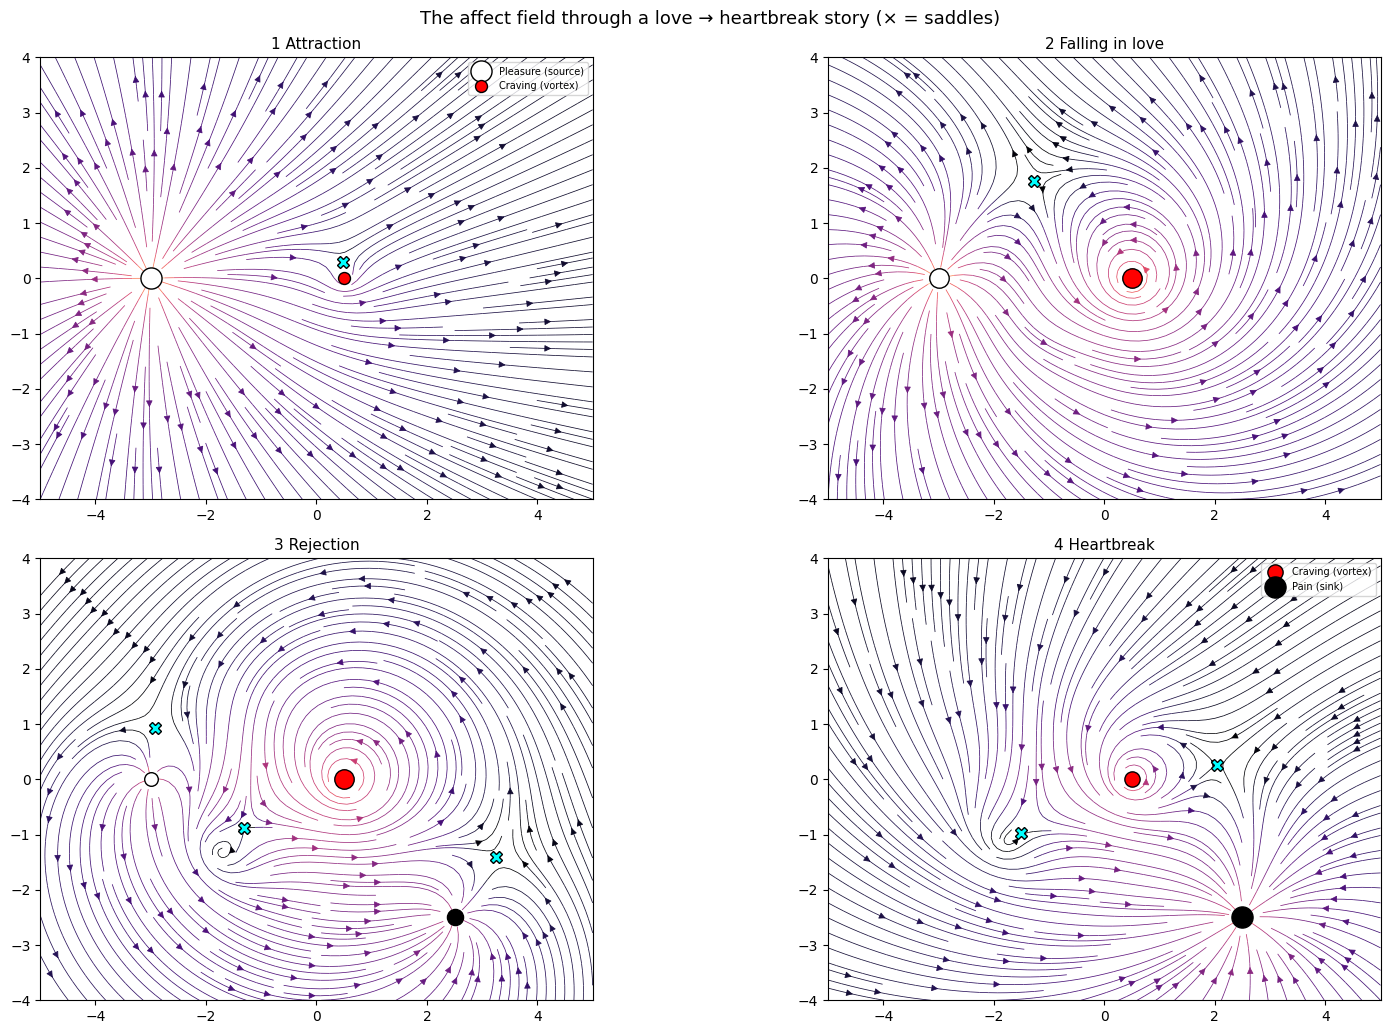

In [5]:
%matplotlib inline

# Configuration: (location, residue of V=u-iw at full strength)
poles0 = {"Pleasure (source)": (-3.0+0j,  2/(2*np.pi)),
          "Craving (vortex)":  ( 0.5+0j, -2j/(2*np.pi)),
          "Pain (sink)":       ( 2.5-2.5j, -1.5/(2*np.pi))}
a_saddle, k0, s = -1-0.5j, 0.6, 1.0

# story stages: strength multipliers (pleasure, craving, pain, fear-saddle)
stages = {"1 Attraction":(1.2,0.1,0.0,0.0),
          "2 Falling in love":(1.0,1.0,0.0,0.3),
          "3 Rejection":(0.3,1.0,0.6,1.0),
          "4 Heartbreak":(0.0,0.5,1.2,0.5)}

def make(p,q,n,f):
    amps=dict(zip(poles0,(p,q,n))); P={nm:(a,c*amps[nm]) for nm,(a,c) in poles0.items() if amps[nm]>0}
    def V(z):
        out=sum(c/(z-a) for a,c in P.values())*np.ones_like(z)
        return out+k0*f*(z-a_saddle)*np.exp(-np.abs(z-a_saddle)**2/s**2)
    return V,P

def circ(c,r,N=100001):
    t=np.linspace(0,2*np.pi,N); return c+r*np.exp(1j*t),1j*r*np.exp(1j*t),t

def res(V,c,r): z,dz,t=circ(c,r); return np.trapezoid(V(z)*dz,t)/(2j*np.pi)

def W(f,c,r): z,_,_=circ(c,r); a=np.unwrap(np.angle(f(z))); return (a[-1]-a[0])/(2*np.pi)

def zeros(vel,P):
    out=[]
    for x0 in np.linspace(-4.5,4.5,19):
        for y0 in np.linspace(-3.5,3.5,15):
            F=lambda p:[vel(np.array(p[0]+1j*p[1])).real,vel(np.array(p[0]+1j*p[1])).imag]
            p,info,ier,_=fsolve(F,[x0,y0],full_output=True); z=p[0]+1j*p[1]
            if ier==1 and abs(z)<8 and all(abs(z-q)>1e-3 for q in out) and all(abs(z-a)>0.05 for a,_ in P.values()): out.append(z)
    return out

X,Y=np.meshgrid(np.linspace(-5,5,500),np.linspace(-4,4,400)); Zg=X+1j*Y
fig,axs=plt.subplots(2,2,figsize=(17,10.5))
axs=axs.ravel()
cols={"Pleasure (source)":"white","Craving (vortex)":"red","Pain (sink)":"black"}
print(f"{'stage':20s}{'Res pleasure':>14s}{'Res craving':>14s}{'Res pain':>14s}{'W(r=8)':>8s}  stagnation points (saddles / nodes)")

for ax,(name,(p,q,n,f)) in zip(axs,stages.items()):
    V,P=make(p,q,n,f); vel=lambda z,V=V:np.conj(V(z)); F=vel(Zg)
    ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=2.0,linewidth=0.55,norm=plt.Normalize(-1.5,1.0))
    cells=[]
    for nm in poles0:
        if nm in P: R=res(V,P[nm][0],0.4); cells.append(f"{R.real:+.2f}{R.imag:+.2f}j")
        else: cells.append("—")
    zs=zeros(vel,P); sad=[z for z in zs if np.linalg.det(np.array([[ (vel(z+1e-6)-vel(z-1e-6)).real/2e-6,(vel(z+1e-6j)-vel(z-1e-6j)).real/2e-6],[(vel(z+1e-6)-vel(z-1e-6)).imag/2e-6,(vel(z+1e-6j)-vel(z-1e-6j)).imag/2e-6]]))<0]
    print(f"{name:20s}{cells[0]:>14s}{cells[1]:>14s}{cells[2]:>14s}{W(vel,0,8.0):+8.0f}  {len(sad)} / {len(zs)-len(sad)}")
    for nm,(a,c) in poles0.items():
        if nm in P: ax.plot(a.real,a.imag,"o",color=cols[nm],ms=8+6*abs(P[nm][1])/abs(c),mec="k",label=nm)
    for z in zs:
        d=np.array([[ (vel(z+1e-6)-vel(z-1e-6)).real/2e-6,(vel(z+1e-6j)-vel(z-1e-6j)).real/2e-6],[(vel(z+1e-6)-vel(z-1e-6)).imag/2e-6,(vel(z+1e-6j)-vel(z-1e-6j)).imag/2e-6]])
        if np.linalg.det(d)<0 and abs(z.real)<5 and abs(z.imag)<4: ax.plot(z.real,z.imag,"X",color="cyan",ms=9,mec="k")
    ax.set_xlim(-5,5); ax.set_ylim(-4,4); ax.set_aspect("equal"); ax.set_title(name,fontsize=11); ax.set_facecolor("#fff")

axs[0].legend(loc="upper right",fontsize=7)
axs[3].legend(loc="upper right",fontsize=7)

fig.suptitle("The affect field through a love → heartbreak story (× = saddles)",fontsize=13)
fig.tight_layout()
fig.show()
fig.savefig("affect_story_fields.svg",dpi=110)

Saddle-node birth at the sink: m_sn = 0.1454  (u = 0.129);  zeros near sink: 0 below -> 2 above
Saddle absorbed by the vortex at u = 0.862  (G = 0.251, m = 3.45)

frame                                                m     G |Res| sink |Res| vort sad/node  idx  W(9)  saddle→sink  saddle→vortex
1  Craving only (vortex)                          0.00  2.00      0.000      0.311    0/1     +1    +1            —              —
2  Saddle-node born at the sink (pain onset)      0.22  2.00      0.034      0.311    1/2     +1    +1         0.40           4.10
3  Sink and saddle separate                       1.00  2.00      0.156      0.311    1/2     +1    +1         1.84           3.69
4  Sink fully visible                             2.00  2.00      0.311      0.311    1/2     +1    +1         2.92           2.92
5  Sink grows, craving fading                     3.00  1.00      0.467      0.156    1/2     +1    +1         3.92           1.29
6  Sink dominates, craving gone                   4

/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/465459337.py:90: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


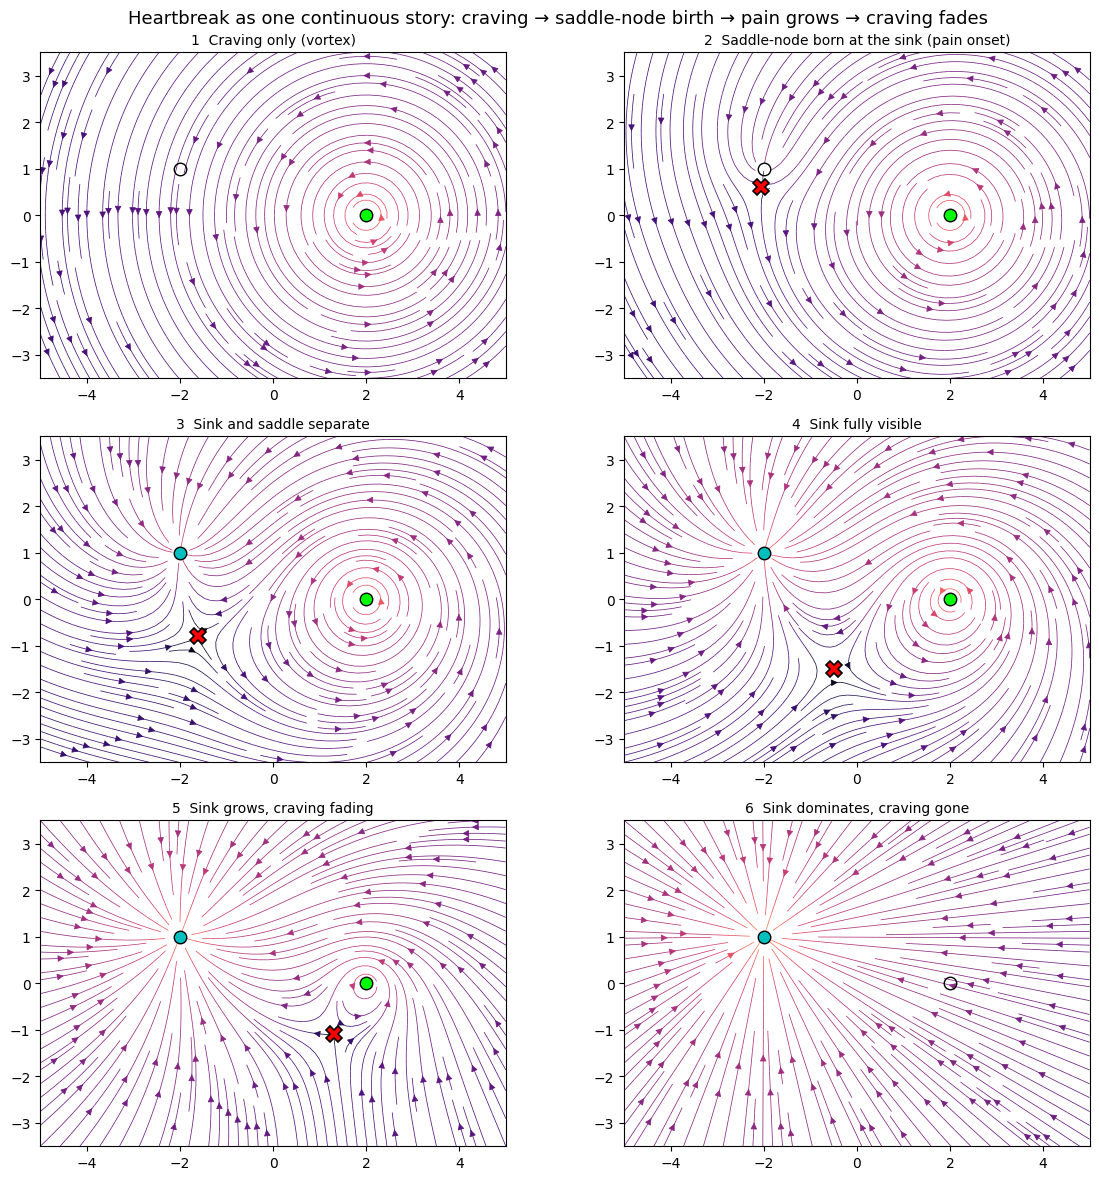

In [6]:
%matplotlib inline

a, b = -2+1j, 2+0j            # pain sink, craving vortex
eps_s = eps_v = 0.15
def vel(z, m, g):
    sink = -(m/(2*np.pi))*(z-a)/(np.abs(z-a)**2+eps_s**2)
    vort = (g/(2*np.pi))*1j*(z-b)/(np.abs(z-b)**2+eps_v**2)
    return sink+vort

# one continuous schedule u in [0,1]: pain rises, then craving fades
def m_of(u): return 0.0 if u<=0.1 else (2.0*(u-0.1)/0.4 if u<=0.5 else 2.0+2.0*(u-0.5)/0.5)
def g_of(u): return 2.0 if u<=0.6 else max(0.0,2.0*(1-(u-0.6)/0.3))

def zeros(f, local=None):
    out=[]; starts=[]
    if local is None:
        starts=[(x,y) for x in np.linspace(-4.5,4.5,19) for y in np.linspace(-3.5,3.5,15)]
        starts+=[(c.real+dx,c.imag+dy) for c in (a,b) for dx in np.linspace(-1,1,9) for dy in np.linspace(-1,1,9)]
    else: starts=[(local.real+dx,local.imag+dy) for dx in np.linspace(-1.2,1.2,13) for dy in np.linspace(-1.2,1.2,13)]
    for x0,y0 in starts:
        F=lambda p:[f(p[0]+1j*p[1]).real,f(p[0]+1j*p[1]).imag]
        p,info,ier,_=fsolve(F,[x0,y0],full_output=True); z=p[0]+1j*p[1]
        if ier==1 and np.hypot(*F(p))<1e-9 and abs(z)<8 and all(abs(z-q)>1e-3 for q in out): out.append(z)
    res=[]
    for z in out:
        h=1e-6; J=np.array([[(f(z+h)-f(z-h)).real/(2*h),(f(z+1j*h)-f(z-1j*h)).real/(2*h)],[(f(z+h)-f(z-h)).imag/(2*h),(f(z+1j*h)-f(z-1j*h)).imag/(2*h)]])
        res.append((z,"saddle" if np.linalg.det(J)<0 else "node"))
    return res
    
def circ(c,r,N=20001): th=np.linspace(0,2*np.pi,N); return c+r*np.exp(1j*th),1j*r*np.exp(1j*th),th
def residue(f,c,r): z,dz,th=circ(c,r); return np.trapezoid(np.conj(f(z))*dz,th)/(2j*np.pi)
def W(f,c,r): z,_,_=circ(c,r); an=np.unwrap(np.angle(f(z))); return (an[-1]-an[0])/(2*np.pi)

# ---- birth of the saddle-node at the sink (pain onset), G=2 ----
nz=lambda m:len(zeros(lambda z:vel(z,m,2.0),local=a))
lo,hi=0.0,2.0
for _ in range(22):
    mid=(lo+hi)/2
    if nz(mid)>=2: hi=mid
    else: lo=mid
m_sn=hi; u_birth=0.1+m_sn/2.0*0.4
print(f"Saddle-node birth at the sink: m_sn = {m_sn:.4f}  (u = {u_birth:.3f});  zeros near sink: {nz(m_sn*0.9)} below -> {nz(m_sn*1.1)} above")

# ---- death of the saddle at the vortex (craving ends) ----
hasS=lambda u:any(k=="saddle" for z,k in zeros(lambda z:vel(z,m_of(u),g_of(u))))
lo,hi=0.6,0.99
for _ in range(14):
    mid=(lo+hi)/2
    if hasS(mid): lo=mid
    else: hi=mid
u_death=lo; print(f"Saddle absorbed by the vortex at u = {u_death:.3f}  (G = {g_of(u_death):.3f}, m = {m_of(u_death):.2f})")

frames=[("1  Craving only (vortex)",                                0.05),
        ("2  Saddle-node born at the sink (pain onset)",            u_birth+0.015),
        ("3  Sink and saddle separate",                              0.30),
        ("4  Sink fully visible",                                    0.50),
        ("5  Sink grows, craving fading",                            0.75),
        ("6  Sink dominates, craving gone",                          1.00)]
print(f"\n{'frame':48s}{'m':>6s}{'G':>6s}{'|Res| sink':>11s}{'|Res| vort':>11s}{'sad/node':>9s}{'idx':>5s}{'W(9)':>6s}  saddle→sink  saddle→vortex")
X,Y=np.meshgrid(np.linspace(-5,5,300),np.linspace(-3.5,3.5,210))
Zg=X+1j*Y

def draw(ax,u,title,dens=1.6):
    m,g=m_of(u),g_of(u)
    f=lambda z:vel(z,m,g); F=f(Zg)
    ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=dens,linewidth=0.55,norm=plt.Normalize(-2,1))
    st=zeros(f); sad=[z for z,k in st if k=="saddle"]
    for z in sad: ax.plot(z.real,z.imag,"X",color="red",ms=11,mec="k",mew=1.2)
    rs,rv=abs(residue(f,a,1.0)),abs(residue(f,b,1.0))
    ax.plot(a.real,a.imag,"o",mfc="c" if rs>0.05 else "none",mec="k",ms=9)
    ax.plot(b.real,b.imag,"o",mfc="lime" if rv>0.05 else "none",mec="k",ms=9)
    ax.set_facecolor("#fff")
    ax.set_aspect("equal")
    ax.set_xlim(-5,5)
    ax.set_ylim(-3.5,3.5)
    ax.set_title(title,fontsize=10)
    return m,g,rs,rv,st,sad,f

fig,axs=plt.subplots(3,2,figsize=(12,12))
axs=axs.ravel()
for ax,(nm,u) in zip(axs,frames):
    m,g,rs,rv,st,sad,f = draw(ax,u,f"{nm}")
    nn=len(st)-len(sad)
    d1=f"{abs(sad[0]-a):.2f}" if sad else "—"
    d2=f"{abs(sad[0]-b):.2f}" if sad else "—"
    print(f"{nm:48s}{m:6.2f}{g:6.2f}{rs:11.3f}{rv:11.3f}{len(sad):5d}/{nn:<3d}{nn-len(sad):+5d}{W(f,0,9.0):+6.0f}  {d1:>11s}  {d2:>13s}")

fig.suptitle("Heartbreak as one continuous story: craving → saddle-node birth → pain grows → craving fades", fontsize=13)
fig.tight_layout()
fig.show()
fig.savefig("affect_heartbreak.svg",dpi=115)

This heartbreak story where the brain concludes "I want it, but cannot get it" transitions through a saddle-node bifurcation into Grief/Heartbreak:

*vortex of craving → saddle-node birth → pain as sink grows → craving fades → fix point pain remains*

It is similar to desire (and appetite) in general which does not always lead to heartbreak, but also to anger if omitted suddenly. If the brain concludes "I want it, but something is blocking it", it transitions into Anger/Rage 

*desire → anger if desire is blocked and expected pleasure is omitted → fix point of anger remains*

In both case the craving is turned into obsessive thinking about the desired object, but heartbreak is direct inwards and results in frustration while anger is directed outwards against the perceived barrier.

This model is general enough to describe any psychological state where an organism's internal model undergoes qualitative shifts under homeostatic stress.

* Addiction is a hyper-stable inwards spiral sink (combines the sink of a pain, the spiral sink of rumination, and the vortex of craving)

* Depression is a flattened, dead gradient where velocity of the field approaches zero

* Panic is an exploding growth of a singularity and its basin

* Flow is an analytic smoothing of the manifold

The full love story from start (falling in love) to end (heartbreak):

stage                    s     G     m |Res| src |Res| vort |Res| sink sad/node  idx  W(12)
1 Attraction          2.50  0.40  0.00     0.389      0.062      0.000    1/2     +1     +1
2 Falling in love     2.00  1.50  0.00     0.311      0.233      0.000    1/2     +1     +1
3 Being in love       0.80  3.00  0.00     0.125      0.467      0.000    1/2     +1     +1
4 Onset of pain       0.50  2.80  0.60     0.078      0.436      0.093    2/2     +0     +1
5 Rejection           0.00  2.50  1.80     0.000      0.389      0.280    1/2     +1     +1
6 Heartbreak          0.00  0.30  4.00     0.000      0.047      0.623    0/1     +1     +1


/var/folders/cd/3gww33t55rs870r4_x2kzkch0000gn/T/ipykernel_54164/2591438803.py:73: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


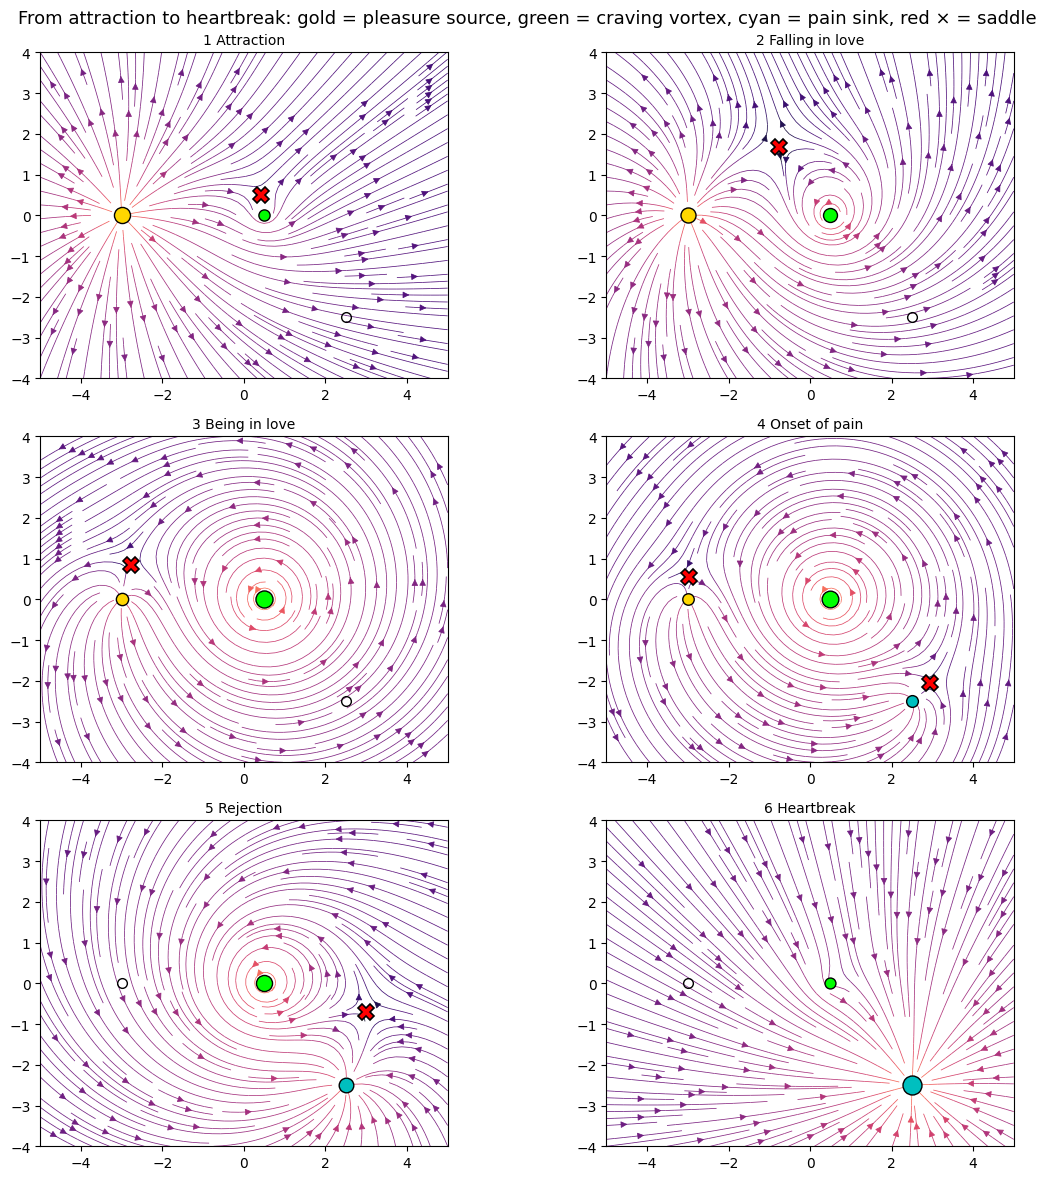

In [7]:
%matplotlib inline
from scipy.optimize import fsolve

P, V, A = -3.0+0j, 0.5+0j, 2.5-2.5j       # pleasure source, craving vortex, pain sink

eps=0.15
def vel(z,s,G,m):
    src =  (s/(2*np.pi))*(z-P)/(np.abs(z-P)**2+eps**2)
    vort=  (G/(2*np.pi))*1j*(z-V)/(np.abs(z-V)**2+eps**2)
    sink= -(m/(2*np.pi))*(z-A)/(np.abs(z-A)**2+eps**2)
    return src+vort+sink

# keyframes: (u, source s, vortex G, sink m) = the six stages
stages=[("1 Attraction",0.0,2.5,0.4,0.0),
        ("2 Falling in love",0.2,2.0,1.5,0.0),
        ("3 Being in love",0.4,0.8,3.0,0.0),
        ("4 Onset of pain",0.6,0.5,2.8,0.6),
        ("5 Rejection",0.8,0.0,2.5,1.8),
        ("6 Heartbreak",1.0,0.0,0.3,4.0)]

ku=np.array([s[1] for s in stages]); K=np.array([[s[2],s[3],s[4]] for s in stages])

def strengths(u):                          # smoothstep between keyframes -> no abrupt jumps
    i=min(np.searchsorted(ku,u,side="right")-1,len(ku)-2); t=(u-ku[i])/(ku[i+1]-ku[i]); t=t*t*(3-2*t)
    return tuple(K[i]*(1-t)+K[i+1]*t)

def zeros(f):
    starts=[(x,y) for x in np.linspace(-4.5,4.5,19) for y in np.linspace(-3.5,3.5,15)]
    starts+=[(c.real+dx,c.imag+dy) for c in (P,V,A) for dx in np.linspace(-1,1,7) for dy in np.linspace(-1,1,7)]
    out=[]
    for x0,y0 in starts:
        F=lambda p:[f(p[0]+1j*p[1]).real,f(p[0]+1j*p[1]).imag]
        p,info,ier,_=fsolve(F,[x0,y0],full_output=True); z=p[0]+1j*p[1]
        if ier==1 and np.hypot(*F(p))<1e-9 and abs(z)<8 and all(abs(z-q)>1e-3 for q in out): out.append(z)
    res=[]
    for z in out:
        h=1e-6; J=np.array([[(f(z+h)-f(z-h)).real/(2*h),(f(z+1j*h)-f(z-1j*h)).real/(2*h)],[(f(z+h)-f(z-h)).imag/(2*h),(f(z+1j*h)-f(z-1j*h)).imag/(2*h)]])
        res.append((z,"saddle" if np.linalg.det(J)<0 else "node"))
    return res
    
def circ(c,r,N=20001): th=np.linspace(0,2*np.pi,N); return c+r*np.exp(1j*th),1j*r*np.exp(1j*th),th

def residue(f,c,r=1.0): z,dz,th=circ(c,r); return np.trapezoid(np.conj(f(z))*dz,th)/(2j*np.pi)

def W(f,c,r): z,_,_=circ(c,r); an=np.unwrap(np.angle(f(z))); return (an[-1]-an[0])/(2*np.pi)

us=np.unique(np.concatenate([np.linspace(0,1,49),ku])); data={}
for u in us:
    s,G,m=strengths(u); f=lambda z,s=s,G=G,m=m:vel(z,s,G,m); data[round(u,4)]=zeros(f)
cnt=np.array([(sum(k=="saddle" for _,k in data[round(u,4)]),sum(k=="node" for _,k in data[round(u,4)])) for u in us])

print(f"{'stage':20s}{'s':>6s}{'G':>6s}{'m':>6s}{'|Res| src':>10s}{'|Res| vort':>11s}{'|Res| sink':>11s}{'sad/node':>9s}{'idx':>5s}{'W(12)':>7s}")
for (nm,u,s,G,m) in stages:
    f=lambda z:vel(z,s,G,m); st=data[round(u,4)]; ns=sum(k=="saddle" for _,k in st); nn=len(st)-ns
    print(f"{nm:20s}{s:6.2f}{G:6.2f}{m:6.2f}{abs(residue(f,P)):10.3f}{abs(residue(f,V)):11.3f}{abs(residue(f,A)):11.3f}{ns:5d}/{nn:<3d}{nn-ns:+5d}{W(f,0,12.0):+7.0f}")

X,Y=np.meshgrid(np.linspace(-5,5,300),np.linspace(-4,4,240)); Zg=X+1j*Y
def draw(ax,u,title,dens=1.6):
    s,G,m=strengths(u); f=lambda z:vel(z,s,G,m); F=f(Zg)
    ax.streamplot(X,Y,F.real,F.imag,color=np.log10(np.abs(F)+1e-9),cmap="magma",density=dens,linewidth=0.55,norm=plt.Normalize(-2,1))
    for z,k in data[round(u,4)]:
        if k=="saddle" and abs(z.real)<5 and abs(z.imag)<4: ax.plot(z.real,z.imag,"X",color="red",ms=11,mec="k",mew=1.2)
    for c,val,col in ((P,s,"gold"),(V,G,"lime"),(A,m,"c")):
        ax.plot(c.real,c.imag,"o",mfc=col if val>0.15 else "none",mec="k",ms=7+2.2*val**0.8)
    ax.set_facecolor("#fff"); ax.set_aspect("equal"); ax.set_xlim(-5,5); ax.set_ylim(-4,4); ax.set_title(title,fontsize=10)

fig,axs=plt.subplots(3,2,figsize=(12,12))
axs=axs.ravel()
for ax,(nm,u,s,G,m) in zip(axs,stages): draw(ax,u,f"{nm}")

fig.suptitle("From attraction to heartbreak: gold = pleasure source, green = craving vortex, cyan = pain sink, red × = saddle",fontsize=13)
fig.tight_layout();
fig.show()
fig.savefig("affect_lovestory.svg",dpi=112)